In [3]:
import kagglehub

path = kagglehub.dataset_download("subhajournal/busi-breast-ultrasound-images-dataset")

print("Path to dataset files:", path)

100%|██████████| 195M/195M [00:02<00:00, 89.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/subhajournal/busi-breast-ultrasound-images-dataset/versions/1


In [4]:
import cv2
import matplotlib.pyplot as plt
import os
import random
import numpy as np
import pandas as pd
from glob import glob
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision.models import (
    efficientnet_b0, EfficientNet_B0_Weights,
    densenet121, DenseNet121_Weights,
    convnext_tiny, ConvNeXt_Tiny_Weights
)

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay, accuracy_score
from sklearn.model_selection import StratifiedKFold, train_test_split


class CFG:

    DATASET_PATH = "/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT"
    SEARCH_ROOTS = [DATASET_PATH, "/kaggle/input", "/root/.cache/kagglehub/datasets/subhajournal/busi-breast-ultrasound-images-dataset/versions/1"]
    IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp")
    IMG_SIZE = 224
    SEED = 42
    NUM_WORKERS = 2
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    SSL_BATCH = 32
    SSL_EPOCHS = 150
    SSL_LR = 1e-4
    SSL_WEIGHT_DECAY = 1e-4
    TEMP = 0.2
    LP_BATCH = 32
    LP_EPOCHS = 30
    LP_LR = 1e-3
    FT_BATCH = 32
    FT_EPOCHS = 25
    FT_LR = 3e-5
    USE_FOCAL = False
    VAL_SIZE = 0.2
    TEST_SIZE = 0.1
    ROI_CROP_PROB = 0.7
    INTENSITY_GAIN_RANGE = (0.8, 1.2)
    INTENSITY_BIAS_RANGE = (-15, 15)
    BG_ERASE_PROB = 0.4
    BG_ERASE_RATE = 0.1
    OUT_DIR = "/kaggle/working/busi_ssl_hybrid"
    SSL_CKPT = "ssl_hybrid_backbone.pth"
    LP_CKPT = "linear_probe_hybrid.pth"
    FT_CKPT = "finetune_hybrid.pth"

os.makedirs(CFG.OUT_DIR, exist_ok=True)

def set_seed(seed=CFG.SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [5]:
# =======================================
# 2. Data Indexing and Splitting
# =======================================
CLASS_MAP = {"benign": 0, "malignant": 1, "normal": 2}
INV_CLASS = {v: k for k, v in CLASS_MAP.items()}

def find_busi_root():
    candidates = []
    for root in CFG.SEARCH_ROOTS:
        if not os.path.exists(root):
            continue
        for p in glob(os.path.join(root, "**"), recursive=True):
            if all(os.path.isdir(os.path.join(p, c)) for c in ["benign", "malignant", "normal"]):
                candidates.append(p)
    if len(candidates) == 0:
        print("[WARN] BUSI root not found automatically.")
        return None
    candidates.sort(key=len)
    print("[INFO] Using BUSI root:", candidates[0])
    return candidates[0]

BUSI_ROOT = find_busi_root()
assert BUSI_ROOT is not None, "BUSI dataset path not found."

def match_mask_path(img_path: str):
    base, ext = os.path.splitext(img_path)
    p1 = base + "_mask" + ext
    if os.path.exists(p1): return p1
    folder = os.path.dirname(img_path)
    fname = os.path.basename(base) + "_mask" + ext
    for sub in ["mask", "masks", "GT", "ground_truth", "ground-truth"]:
        p2 = os.path.join(folder, sub, fname)
        if os.path.exists(p2): return p2
    p3 = base + ext
    if os.path.exists(p3) and ("mask" in p3.lower()): return p3
    return None

def build_index(root=BUSI_ROOT):
    rows = []
    for cls in CLASS_MAP.keys():
        for img_path in glob(os.path.join(root, cls, "**", "*"), recursive=True):
            if os.path.isdir(img_path): continue
            if not img_path.lower().endswith(CFG.IMG_EXTS): continue
            if "mask" in os.path.basename(img_path).lower(): continue
            mask_path = match_mask_path(img_path)
            if mask_path is None:
                if cls != "normal": pass
            rows.append({"image": img_path, "mask": mask_path if mask_path else "", "label": CLASS_MAP[cls], "cls": cls})
    df = pd.DataFrame(rows)
    print("Counts:\n", df["cls"].value_counts())
    return df

df_all = build_index(BUSI_ROOT)

if CFG.TEST_SIZE > 0:
    train_val_df, test_df = train_test_split(df_all, test_size=CFG.TEST_SIZE, stratify=df_all['cls'], random_state=CFG.SEED)
    train_df, val_df = train_test_split(train_val_df, test_size=CFG.VAL_SIZE / (1 - CFG.TEST_SIZE), stratify=train_val_df['cls'], random_state=CFG.SEED)
else:
    train_df, val_df = train_test_split(df_all, test_size=CFG.VAL_SIZE, stratify=df_all['cls'], random_state=CFG.SEED)
    test_df = None

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df) if test_df is not None else 0}")

[INFO] Using BUSI root: /root/.cache/kagglehub/datasets/subhajournal/busi-breast-ultrasound-images-dataset/versions/1/Dataset_BUSI_with_GT
Counts:
 cls
benign       437
malignant    210
normal       133
Name: count, dtype: int64
Train samples: 546 | Val samples: 156 | Test samples: 78


In [ ]:
# =========================================
# 3. Datasets, Models and Loss Functions
# =========================================
class USMaskSSL(Dataset):
    def __init__(self, df, size=CFG.IMG_SIZE, ssl=True):
        self.df = df
        self.size = size
        self.ssl = ssl

    def _read_gray(self, p):
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        return img

    def _roi_center(self, m):
        if m.max()==0: return self.size//2, self.size//2
        y,x = np.where(m>0)
        return int(x.mean()), int(y.mean())

    def _resize(self, x, m):
        x = cv2.resize(x, (self.size, self.size), interpolation=cv2.INTER_AREA)
        m = cv2.resize(m, (self.size, self.size), interpolation=cv2.INTER_NEAREST)
        return x, m

    def _aug_once(self, x, m):
        x, m = self._resize(x, m)

        if random.random() < 0.5:
            x = np.flip(x, 1)
            m = np.flip(m, 1)

        angle = random.uniform(-5, 5)
        M = cv2.getRotationMatrix2D((self.size / 2, self.size / 2), angle, 1.0)
        x = cv2.warpAffine(x, M, (self.size, self.size), flags=cv2.INTER_AREA, borderMode=cv2.BORDER_REPLICATE)
        m = cv2.warpAffine(m, M, (self.size, self.size), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REPLICATE)

        g0, g1 = CFG.INTENSITY_GAIN_RANGE
        gain = g0 + (g1 - g0) * random.random()
        b0, b1 = CFG.INTENSITY_BIAS_RANGE
        bias = np.random.randint(b0, b1 + 1)
        x = np.clip(x.astype(np.float32) * gain + bias, 0, 255).astype(np.uint8)

        if random.random() < CFG.BG_ERASE_PROB and m.max() > 0:
            bg = (m == 0)
            erase = np.random.rand(*bg.shape) < CFG.BG_ERASE_RATE
            x[bg & erase] = np.median(x)

        x = x.astype(np.float32) / 255.0
        m = (m > 0).astype(np.float32)
        c2 = np.stack([x, m], axis=0)
        return torch.from_numpy(c2)

    def _ensure_mask(self, m, shape):
        if m is None: return np.zeros(shape, dtype=np.uint8)
        return (m > 0).astype(np.uint8) * 255

    def _load_pair(self, row):
        x = self._read_gray(row["image"])
        m = self._read_gray(row["mask"]) if row["mask"] else None
        if x is None: raise FileNotFoundError(row["image"])
        m = self._ensure_mask(m, x.shape)
        return x, m

    def __getitem__(self, idx):
        row = self.df.iloc[idx]; x, m = self._load_pair(row)
        if self.ssl:
            v1 = self._aug_once(x, m); v2 = self._aug_once(x, m)
            return v1, v2
        else:
            img = self._aug_once(x, m)
            label = int(row["label"]) if "label" in row else -1
            return img, label

    def __len__(self):
        return len(self.df)

class USMaskSup(USMaskSSL):
    def __init__(self, df, size=CFG.IMG_SIZE, ssl=False):
        super().__init__(df, size=size, ssl=ssl)

class ProjHead(nn.Module):
    def __init__(self, d, out):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, d), nn.ReLU(inplace=True), nn.Linear(d, out))
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)


class HybridBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.effnet = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.effnet.features[0][0] = nn.Conv2d(2, 32, kernel_size=3, stride=2, padding=1, bias=False)
        self.effnet.classifier = nn.Identity()
        self.effnet_dim = 1280

        self.densenet = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
        self.densenet.features.conv0 = nn.Conv2d(2, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.densenet.classifier = nn.Identity()
        self.densenet_dim = 1024

        self.convnext = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        self.convnext.features[0][0] = nn.Conv2d(2, 96, kernel_size=4, stride=4)
        self.convnext.classifier = nn.Identity()
        self.convnext_dim = 768


        self.pooler = nn.AdaptiveAvgPool2d(1)

        self.total_dim = self.effnet_dim + self.densenet_dim + self.convnext_dim
        print(f"[INFO] HybridBackbone initialized. Embedding dim: {self.total_dim}")

    def forward(self, x):
        h_eff = self.effnet(x)

        h_dense_feats = self.densenet.features(x)
        h_dense = F.relu(h_dense_feats, inplace=True)
        h_dense = self.pooler(h_dense).flatten(1) 

        h_conv_feats = self.convnext.features(x)
        h_conv = self.pooler(h_conv_feats).flatten(1)

        return torch.cat([h_eff, h_dense, h_conv], dim=1)

class Classifier(nn.Module):
    def __init__(self, backbone, num_classes=3, embedding_dim=1280):
        super().__init__()
        self.backbone = backbone
        self.fc = nn.Linear(embedding_dim, num_classes)

    def forward(self, x):
        h = self.backbone(x)
        return self.fc(h)

def nt_xent(z1, z2, T=CFG.TEMP):
    z1 = F.normalize(z1, dim=1); z2 = F.normalize(z2, dim=1)
    z = torch.cat([z1, z2], dim=0)
    sim = z @ z.t()
    B = z1.size(0)
    mask = torch.eye(2 * B, device=z.device, dtype=torch.bool)
    sim = sim[~mask].view(2 * B, 2 * B - 1)
    pos = (z1 * z2).sum(dim=1)
    pos = torch.cat([pos, pos], dim=0).unsqueeze(1)
    logits = torch.cat([pos, sim], dim=1) / T
    labels = torch.zeros(2 * B, dtype=torch.long, device=z.device)
    return F.cross_entropy(logits, labels)

def get_class_weights(df):
    counts = df['label'].value_counts().reindex([0,1,2]).fillna(0).values.astype(float)
    weights = counts.sum() / np.clip(counts, 1, None)
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=CFG.DEVICE)

def build_sampler(df):
    labels = df['label'].values
    class_counts = df['label'].value_counts().to_dict()
    iw = {c: 1.0/max(1, class_counts[c]) for c in class_counts}
    sample_weights = np.array([iw[l] for l in labels], dtype=np.float32)
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

In [ ]:
import numpy as np
import tensorflow as tf
from collections import Counter

def print_model_summary_with_layer_counts(model):
    print(f"{'Layer Name':<40} {'Layer Type':<20} {'Output Shape':<25} {'Params':>12}")
    print("="*100)

    layer_types = []

    for layer in model.layers:
        name = layer.name
        layer_type = layer.__class__.__name__
        layer_types.append(layer_type)
        try:
            output_shape = layer.output_shape
        except Exception:
            output_shape = "multiple/output?"
        params = layer.count_params()
        print(f"{name:<40} {layer_type:<20} {str(output_shape):<25} {params:12,}")

    print("="*100)
    total_params = model.count_params()
    trainable_params = np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
    non_trainable_params = np.sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights])
    model_size_mb = total_params * 4 / (1024**2) 

    print(f"Total Layers:           {len(model.layers)}")
    print(f"Total Parameters:       {total_params:,}")
    print(f"Trainable Parameters:   {trainable_params:,}")
    print(f"Non-trainable Params:   {non_trainable_params:,}")
    print(f"Model Size (float32):   {model_size_mb:.2f} MB\n")

    layer_count = Counter(layer_types)
    print("Layer type counts:")
    for layer_type, count in layer_count.most_common():
        print(f"  {layer_type}: {count}")


In [ ]:
# =========================================
# 4. Training and Evaluation Logic
# =======================================
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

def ssl_pretrain(train_df):
    ds = USMaskSSL(train_df, ssl=True)
    dl = DataLoader(ds, batch_size=CFG.SSL_BATCH, shuffle=True, num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True)

    backbone = HybridBackbone().to(CFG.DEVICE)
    EMBEDDING_DIM = backbone.total_dim 

    proj = ProjHead(d=EMBEDDING_DIM, out=128).to(CFG.DEVICE)
    params = list(backbone.parameters()) + list(proj.parameters())
    opt = torch.optim.AdamW(params, lr=CFG.SSL_LR, weight_decay=CFG.SSL_WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler(enabled=(CFG.DEVICE == "cuda"))

    backbone.train(); proj.train()
    best = 1e9
    for epoch in range(1, CFG.SSL_EPOCHS + 1):
        t0 = time.time(); losses = []
        for v1, v2 in dl:
            v1 = v1.to(CFG.DEVICE, non_blocking=True).float(); v2 = v2.to(CFG.DEVICE, non_blocking=True).float()
            with torch.cuda.amp.autocast(enabled=(CFG.DEVICE == "cuda")):
                h1 = backbone(v1); h2 = backbone(v2)
                z1 = proj(h1); z2 = proj(h2)
                loss = nt_xent(z1, z2, T=CFG.TEMP)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item())
        avg = float(np.mean(losses)) if losses else 0.0; dt = time.time() - t0
        print(f"[SSL] Epoch {epoch}/{CFG.SSL_EPOCHS} loss={avg:.4f} time={dt:.1f}s")
        if avg < best:
            best = avg
            torch.save(backbone.state_dict(), os.path.join(CFG.OUT_DIR, CFG.SSL_CKPT))
    print("[SSL] Best loss:", best)

def train_supervised(train_df, val_df):
    stage = 'linear_probe'
    train_ds = USMaskSup(train_df, ssl=False)
    val_ds = USMaskSup(val_df, ssl=False)
    sampler = build_sampler(train_df)
    train_dl = DataLoader(train_ds, batch_size=CFG.LP_BATCH, sampler=sampler, num_workers=CFG.NUM_WORKERS, pin_memory=True)
    val_dl = DataLoader(val_ds, batch_size=CFG.LP_BATCH, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
    lr = CFG.LP_LR; epochs = CFG.LP_EPOCHS; save_ckpt = CFG.LP_CKPT

    backbone = HybridBackbone().to(CFG.DEVICE)
    EMBEDDING_DIM = backbone.total_dim

    ssl_path = os.path.join(CFG.OUT_DIR, CFG.SSL_CKPT)
    if os.path.exists(ssl_path):
        backbone.load_state_dict(torch.load(ssl_path, map_location=CFG.DEVICE))
        print("[INFO] Loaded SSL backbone:", ssl_path)
    else:
        print("[INFO] No SSL backbone found. Starting from ImageNet weights.")

    for param in backbone.parameters(): param.requires_grad = False

    model = Classifier(backbone, num_classes=3, embedding_dim=EMBEDDING_DIM).to(CFG.DEVICE)
    class_weights = get_class_weights(train_df)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    scaler = torch.cuda.amp.GradScaler(enabled=(CFG.DEVICE == "cuda"))

    best_acc = 0.0
    best_path = os.path.join(CFG.OUT_DIR, save_ckpt)

    for epoch in range(1, epochs + 1):
        model.train(); train_losses, correct, total = [], 0, 0
        for (x, y) in train_dl:
            x = x.to(CFG.DEVICE).float(); y = y.to(CFG.DEVICE).long()
            with torch.cuda.amp.autocast(enabled=(CFG.DEVICE=="cuda")):
                logits = model(x); loss = criterion(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            train_losses.append(loss.item()); pred = logits.argmax(1)
            correct += (pred==y).sum().item(); total += y.size(0)
        train_acc = correct/total if total else 0

        model.eval(); val_losses, vcorrect, vtotal, all_logits, all_true = [], 0, 0, [], []
        with torch.no_grad():
            for (x, y) in val_dl:
                x = x.to(CFG.DEVICE).float(); y = y.to(CFG.DEVICE).long()
                with torch.cuda.amp.autocast(enabled=(CFG.DEVICE=="cuda")):
                    logits = model(x); loss = criterion(logits, y)
                val_losses.append(loss.item()); pred = logits.argmax(1)
                vcorrect += (pred==y).sum().item(); vtotal += y.size(0)
                all_logits.append(logits.softmax(1).detach().cpu().numpy())
                all_true.append(y.detach().cpu().numpy())
        val_acc = vcorrect/vtotal if vtotal else 0
        all_logits = np.concatenate(all_logits, axis=0) if len(all_logits) else np.zeros((0,3))
        all_true = np.concatenate(all_true, axis=0) if len(all_true) else np.zeros((0,))
        try:
            ovr_auc = roc_auc_score(all_true, all_logits, multi_class='ovr') if len(np.unique(all_true))>1 else float('nan')
        except Exception: ovr_auc = float('nan')

        print(f"[{stage}] Epoch {epoch} | train_loss={np.mean(train_losses):.4f} acc={train_acc:.3f} | val_loss={np.mean(val_losses):.4f} acc={val_acc:.3f} AUC={ovr_auc:.3f}")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), best_path)

    print(f"[{stage}] Best Val Acc: {best_acc:.4f} | Saved: {best_path}")
    return best_path

def evaluate(model_path, df, stage_name="Evaluation", visualize_cam_examples=5):
    ds = USMaskSup(df, ssl=False)
    dl = DataLoader(ds, batch_size=CFG.LP_BATCH, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)

    backbone = HybridBackbone().to(CFG.DEVICE)
    EMBEDDING_DIM = backbone.total_dim
    model = Classifier(backbone, num_classes=3, embedding_dim=EMBEDDING_DIM).to(CFG.DEVICE)

    model.load_state_dict(torch.load(model_path, map_location=CFG.DEVICE))
    model.eval()

    ALL_P, ALL_Y, ALL_S = [], [], []
    CAM_IMAGES = []
    CAM_LABELS = []

    with torch.no_grad():
        for (x, y) in dl:
            x = x.to(CFG.DEVICE).float(); y = y.to(CFG.DEVICE).long()
            s = model(x).softmax(1); p = s.argmax(1)
            ALL_P.append(p.cpu().numpy()); ALL_Y.append(y.cpu().numpy()); ALL_S.append(s.cpu().numpy())

            if len(CAM_IMAGES) < visualize_cam_examples:
                original_images = x[:, 0, :, :].cpu().numpy() * 255 
                original_images = original_images.astype(np.uint8)
                for i in range(min(x.size(0), visualize_cam_examples - len(CAM_IMAGES))):
                    CAM_IMAGES.append(original_images[i])
                    CAM_LABELS.append(y[i].item())


    y_true = np.concatenate(ALL_Y); y_pred = np.concatenate(ALL_P); y_score = np.concatenate(ALL_S)

    global_accuracy = accuracy_score(y_true, y_pred)

    print(f"\n[{stage_name} Classification Report]")
    print(classification_report(y_true, y_pred, target_names=[INV_CLASS[i] for i in range(3)]))
    print(f"Global Accuracy: {global_accuracy:.4f}")

    cm = confusion_matrix(y_true, y_pred, labels=list(CLASS_MAP.values()))
    fig, ax = plt.subplots(figsize=(8, 8))
    cax = ax.matshow(cm, cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    fig.colorbar(cax)
    ax.set_xticks(np.arange(len(CLASS_MAP.keys())))
    ax.set_yticks(np.arange(len(CLASS_MAP.keys())))
    ax.set_xticklabels(list(CLASS_MAP.keys()))
    ax.set_yticklabels(list(CLASS_MAP.keys()))

    plt.xlabel('Predicted')
    plt.ylabel('True')
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, f'{val}', ha='center', va='center', color='red')
    plt.show()

    try:
        if len(np.unique(y_true)) > 1:
            fig, ax = plt.subplots(figsize=(8, 8))
            for i in range(3):
                y_true_binary = (y_true == i).astype(int)
                y_score_class = y_score[:, i]

                if len(np.unique(y_true_binary)) > 1:
                    RocCurveDisplay.from_predictions(y_true_binary, y_score_class, name=f"Class: {INV_CLASS[i]}", ax=ax)
                else:
                    print(f"Warning: Cannot plot ROC for class {INV_CLASS[i]} as only one class label is present.")

            ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
            plt.title('Receiver Operating Characteristic (ROC) Curve (One-vs-Rest)')
            plt.legend()
            plt.show()

            ovr_auc = roc_auc_score(y_true, y_score, multi_class='ovr')
            print(f"OVR AUC: {ovr_auc:.4f}")
    except Exception as e:
        print(f"AUC/ROC plotting error: {e}")

    try:
        if len(np.unique(y_true)) > 1:
            fig, ax = plt.subplots(figsize=(8, 8))
            for i in range(3):
                y_true_binary = (y_true == i).astype(int)
                y_score_class = y_score[:, i]

                if len(np.unique(y_true_binary)) > 1:
                    precision, recall, _ = precision_recall_curve(y_true_binary, y_score_class)
                    disp = PrecisionRecallDisplay(precision=precision, recall=recall)
                    disp.plot(ax=ax, name=f"Class: {INV_CLASS[i]}")
                else:
                    print(f"Warning: Cannot plot Precision-Recall for class {INV_CLASS[i]} as only one class label is present.")

            plt.title('Precision-Recall Curve (One-vs-Rest)')
            plt.legend()
            plt.show()
    except Exception as e:
        print(f"Precision-Recall plotting error: {e}")

    print(f"\n[{stage_name} Grad-CAM Visualization]")
    model_names = ["effnet", "densenet", "convnext"]
    for i in range(min(visualize_cam_examples, len(ds))):
        img_tensor, true_label = ds[i] 
        img = (img_tensor[0].cpu().numpy() * 255).astype(np.uint8) 

        predicted_label = model(img_tensor.unsqueeze(0).to(CFG.DEVICE).float()).argmax(1).item()

        fig, axes = plt.subplots(1, 4, figsize=(16, 4))
        axes[0].imshow(img, cmap='gray')
        axes[0].set_title(f"Original (True: {INV_CLASS[true_label]}, Pred: {INV_CLASS[predicted_label]})")
        axes[0].axis('off')

        for j, model_name in enumerate(model_names):
            try:
                heatmap = get_cam_heatmap(model, img_tensor, predicted_label, model_name)
                superimposed_img = visualize_cam(img, heatmap)
                axes[j+1].imshow(superimposed_img)
                axes[j+1].set_title(f"{model_name.upper()} CAM")
                axes[j+1].axis('off')
            except Exception as e:
                print(f"Error generating CAM for {model_name} on sample {i}: {e}")
                axes[j+1].set_title(f"{model_name.upper()} CAM (Error)")
                axes[j+1].axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
import torch.nn.functional as F
import cv2
import numpy as np
import matplotlib.pyplot as plt

def get_cam_heatmap(model, img_tensor, target_class, model_name):
    
    model.eval()

    if model_name == 'effnet':
        backbone = model.backbone.effnet
        target_layer = None
        for module in reversed(backbone.features):
            if isinstance(module, torch.nn.Conv2d):
                target_layer = module
                break
            elif isinstance(module, torch.nn.Sequential):
                 for sub_module in reversed(module):
                    if isinstance(sub_module, torch.nn.Conv2d):
                        target_layer = sub_module
                        break
            if target_layer is not None:
                break
        if target_layer is None:
             raise ValueError(f"Could not find a Conv2d layer in {model_name} features.")

    elif model_name == 'densenet':
        backbone = model.backbone.densenet
        target_layer = backbone.features.norm5 
        target_layer = None
        for name, module in backbone.features.named_modules():
             if isinstance(module, torch.nn.Conv2d):
                 target_layer = module 

        if target_layer is None:
             raise ValueError(f"Could not find a Conv2d layer in {model_name} features.")


    elif model_name == 'convnext':
        backbone = model.backbone.convnext
        target_layer = backbone.features[-1][-1] 


    else:
        raise ValueError(f"Unknown model name: {model_name}")

    gradients = None
    activations = None

    def save_gradients(module, grad_input, grad_output):
        nonlocal gradients
        gradients = grad_output[0] 

    def save_activations(module, input, output):
        nonlocal activations
        activations = output

    hook_handle_grad = target_layer.register_backward_hook(save_gradients)
    hook_handle_act = target_layer.register_forward_hook(save_activations)

    img_tensor = img_tensor.unsqueeze(0).to(CFG.DEVICE).float()

    output = model(img_tensor)
    output = output.softmax(1)[:, target_class]

    model.zero_grad()
    output.backward()

    hook_handle_grad.remove()
    hook_handle_act.remove()

    if activations is None or gradients is None:
         print(f"[WARN] Activations or gradients not captured for {model_name}. Check target_layer selection.")
         return np.zeros((CFG.IMG_SIZE, CFG.IMG_SIZE)) 

    weights = F.adaptive_avg_pool2d(gradients, 1)

   
    weights = weights.view(weights.size(0), weights.size(1), 1, 1)
    heatmap = torch.mul(activations, weights).sum(dim=1, keepdim=True).squeeze()
    heatmap = F.relu(heatmap) 

    heatmap = heatmap.detach().cpu().numpy() 
    heatmap = np.maximum(heatmap, 0) 
    if np.max(heatmap) > 0:
        heatmap = heatmap / np.max(heatmap)
    else:
         pass 

    return heatmap

def visualize_cam(original_image, heatmap, alpha=0.4):
    
    heatmap_resized = cv2.resize(heatmap, (original_image.shape[1], original_image.shape[0]))

    original_image_bgr = cv2.cvtColor(original_image, cv2.COLOR_GRAY2BGR)

    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)

    superimposed_img = cv2.addWeighted(original_image_bgr, 1 - alpha, heatmap_colored, alpha, 0)

    return superimposed_img

Device: cuda

Displaying 5 random pairs of augmented images from the training set:


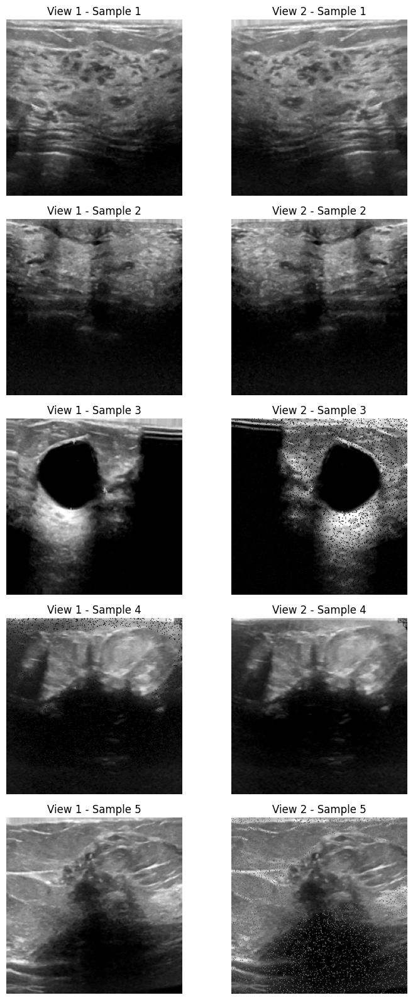


Starting SSL Pretraining with Hybrid Model...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 111MB/s] 


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 101MB/s]


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


...

[linear_probe] Epoch 28 | train_loss=0.0723 acc=0.967 | val_loss=0.1152 acc=0.949 AUC=nan


/tmp/ipython-input-2033767246.py:75: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(CFG.DEVICE=="cuda")):
/tmp/ipython-input-2033767246.py:87: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(CFG.DEVICE=="cuda")):


[linear_probe] Epoch 29 | train_loss=0.0669 acc=0.965 | val_loss=0.1460 acc=0.942 AUC=nan


/tmp/ipython-input-2033767246.py:75: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(CFG.DEVICE=="cuda")):
/tmp/ipython-input-2033767246.py:87: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(CFG.DEVICE=="cuda")):


[linear_probe] Epoch 30 | train_loss=0.0547 acc=0.967 | val_loss=0.1331 acc=0.929 AUC=nan
[linear_probe] Best Val Acc: 0.9615 | Saved: /kaggle/working/busi_ssl_hybrid/linear_probe_hybrid.pth
[INFO] HybridBackbone initialized. Embedding dim: 3072

[Validation (Linear Probe) Classification Report]
              precision    recall  f1-score   support

      benign       0.96      0.98      0.97        87
   malignant       0.95      0.90      0.93        42
      normal       1.00      1.00      1.00        27

    accuracy                           0.96       156
   macro avg       0.97      0.96      0.96       156
weighted avg       0.96      0.96      0.96       156

Global Accuracy: 0.9615


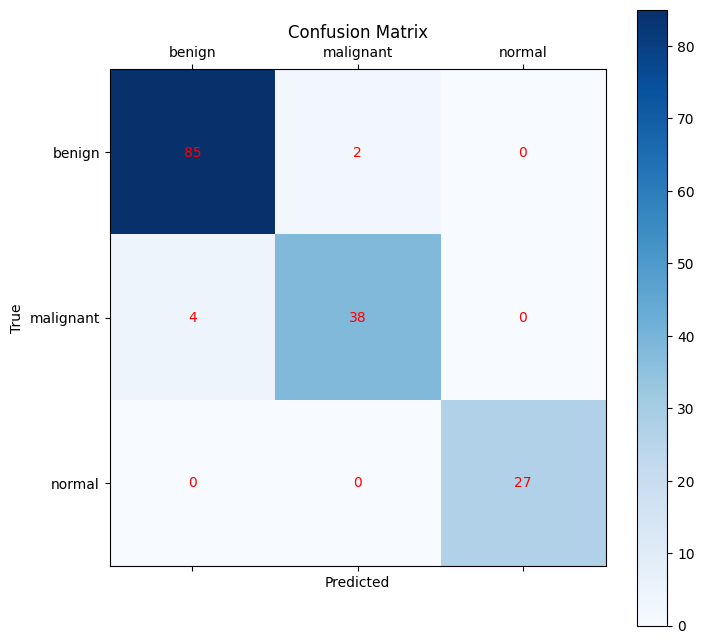

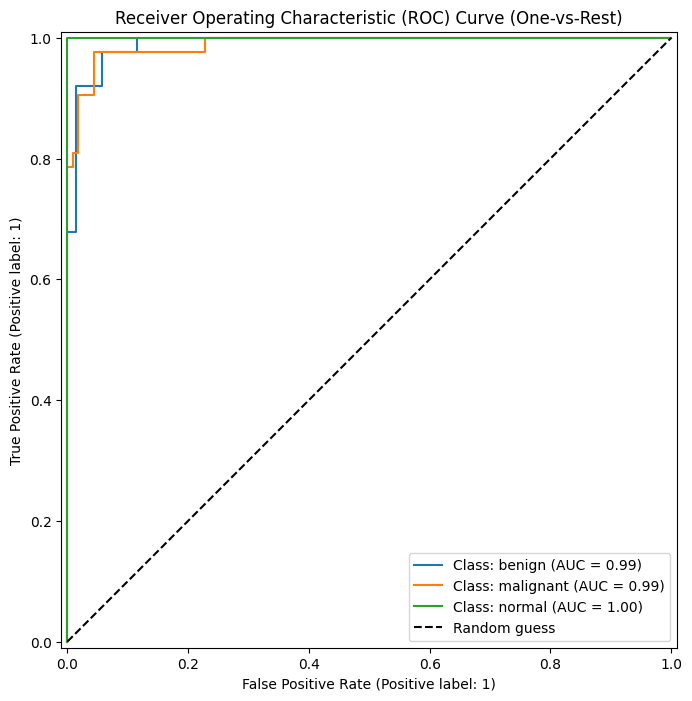

OVR AUC: 0.9934


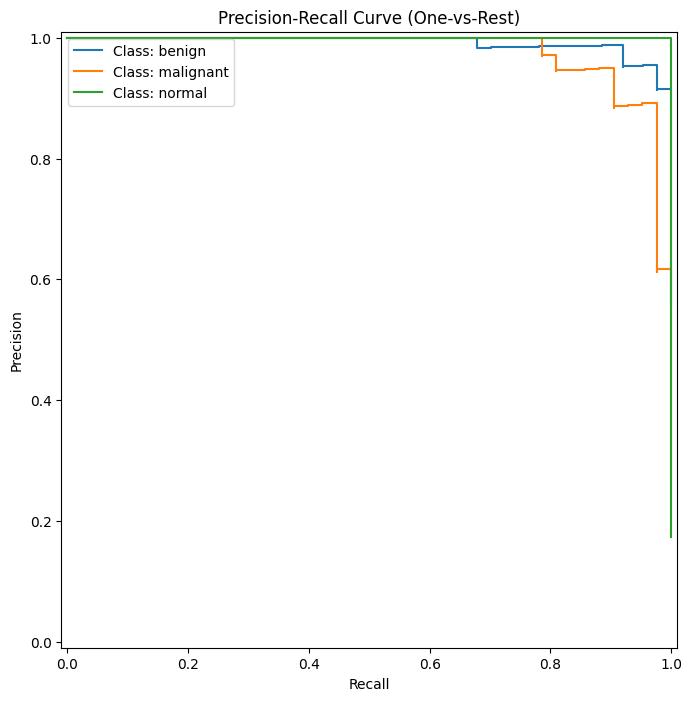


[Validation (Linear Probe) Grad-CAM Visualization]


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


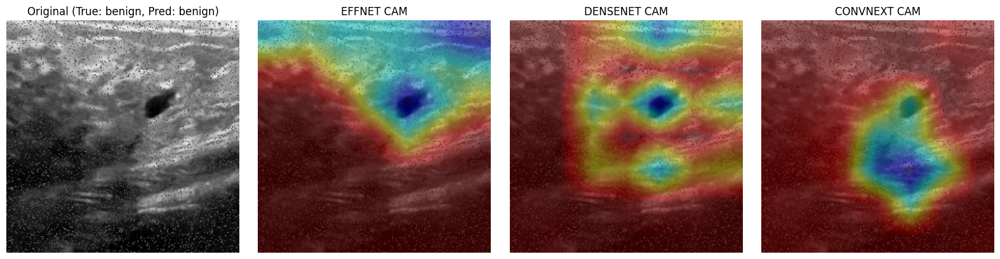

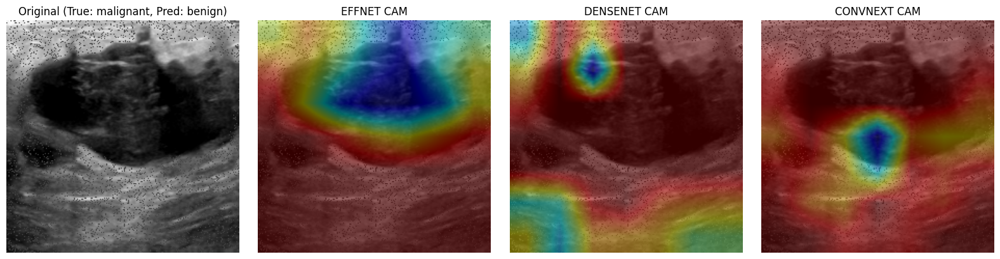

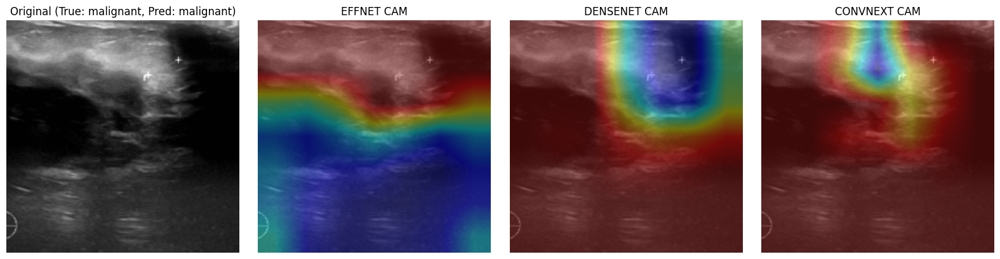

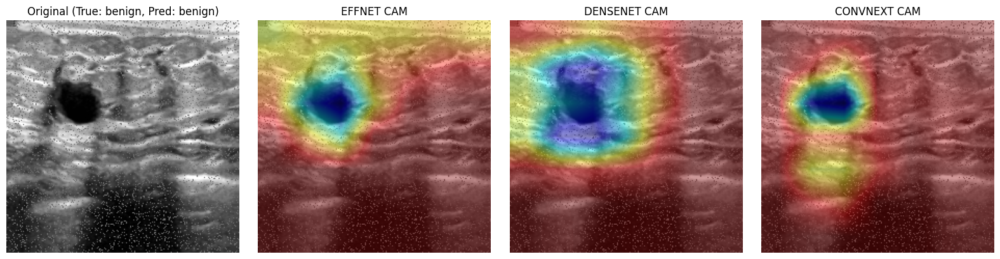

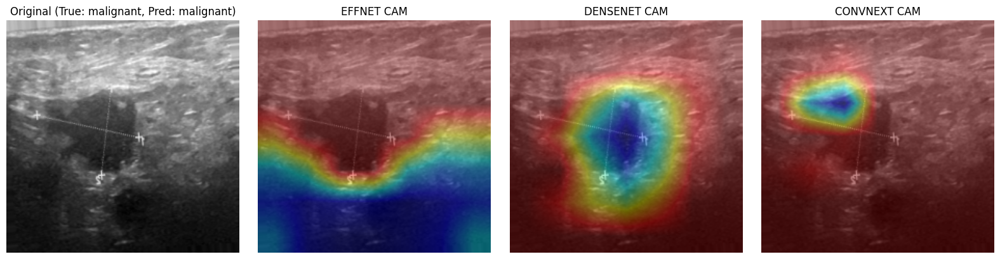


Loading and evaluating Linear Probe model from: /kaggle/working/busi_ssl_hybrid/linear_probe_hybrid.pth
[INFO] HybridBackbone initialized. Embedding dim: 3072

[Validation (Linear Probe) Classification Report]
              precision    recall  f1-score   support

      benign       0.96      0.98      0.97        87
   malignant       0.95      0.90      0.93        42
      normal       1.00      1.00      1.00        27

    accuracy                           0.96       156
   macro avg       0.97      0.96      0.96       156
weighted avg       0.96      0.96      0.96       156

Global Accuracy: 0.9615


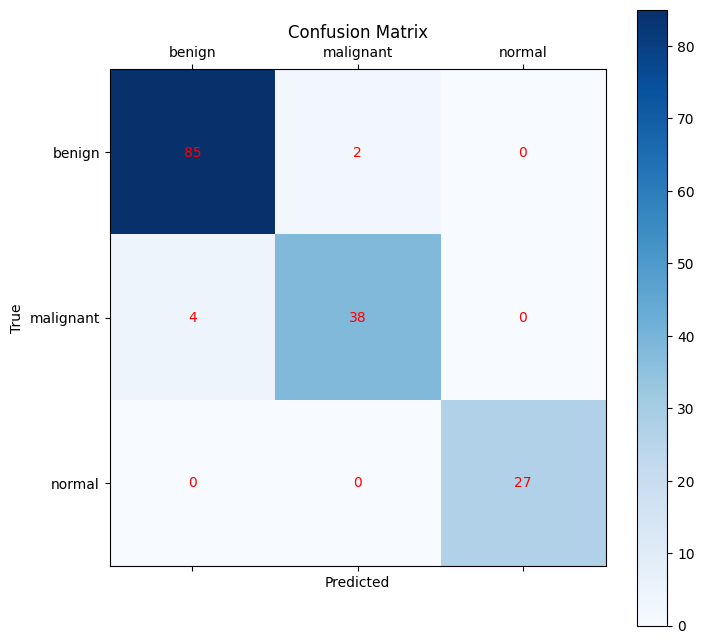

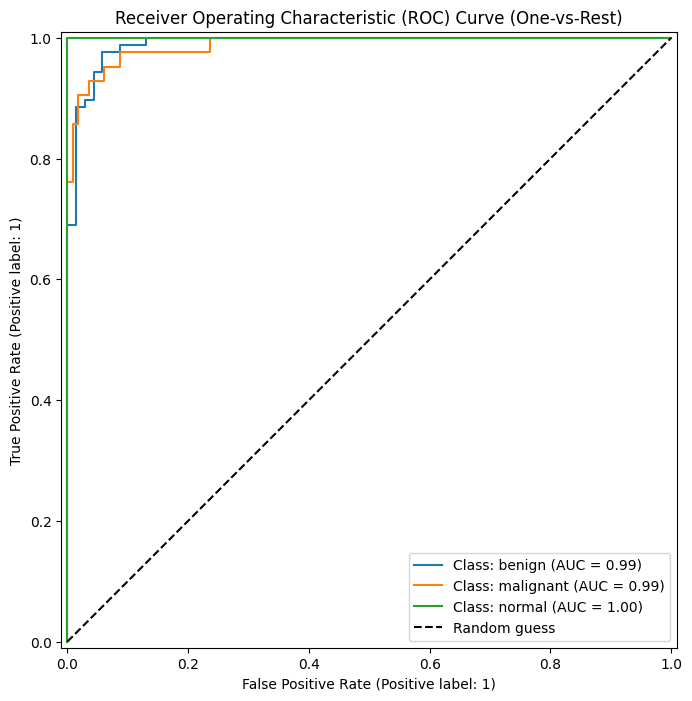

OVR AUC: 0.9929


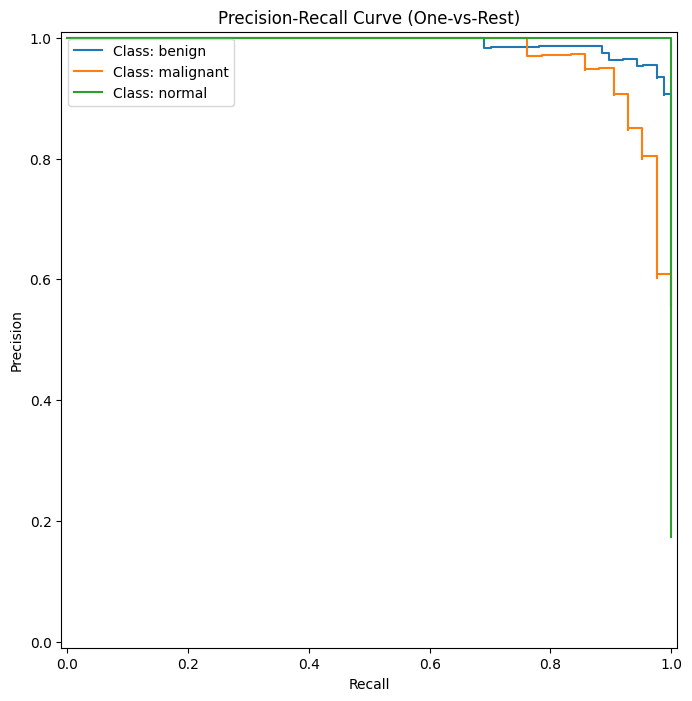


[Validation (Linear Probe) Grad-CAM Visualization]


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


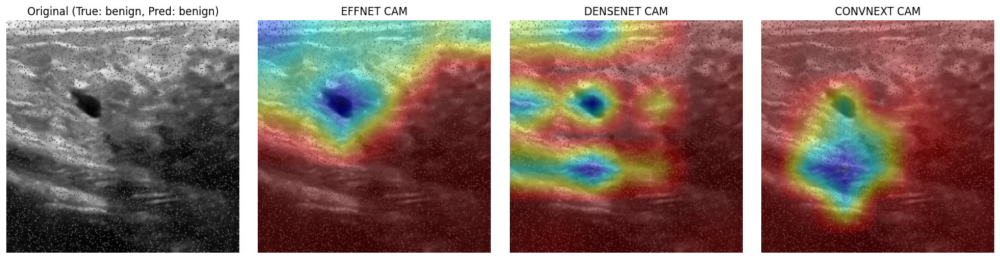

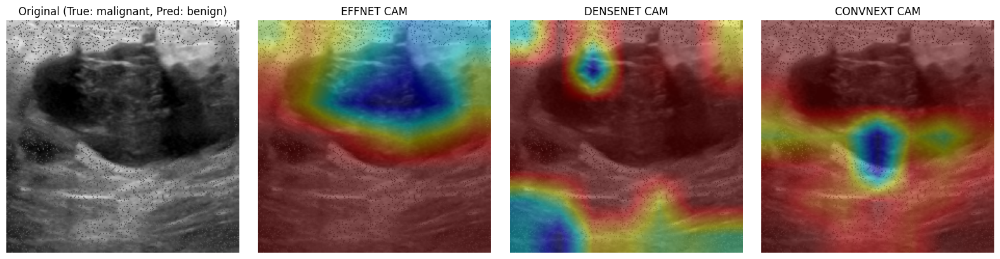

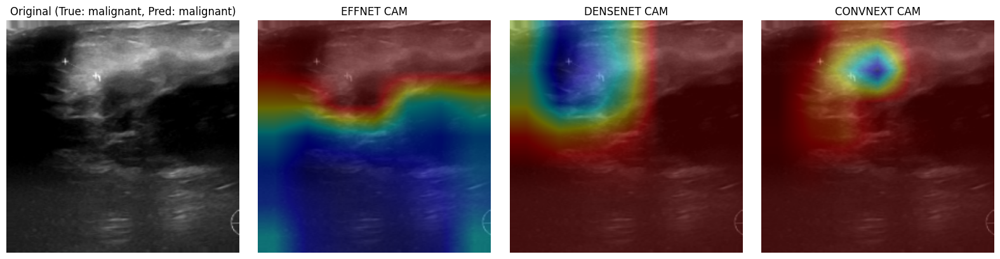

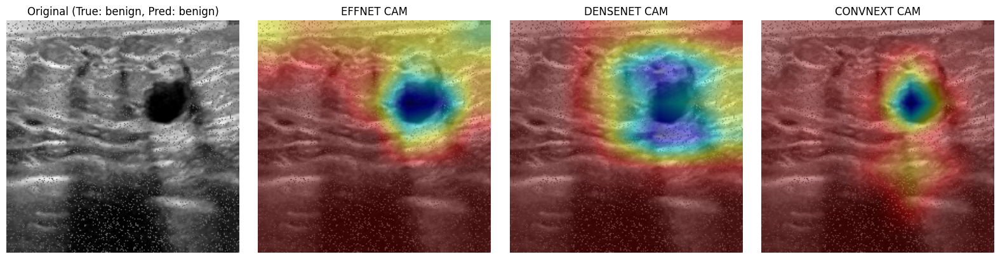

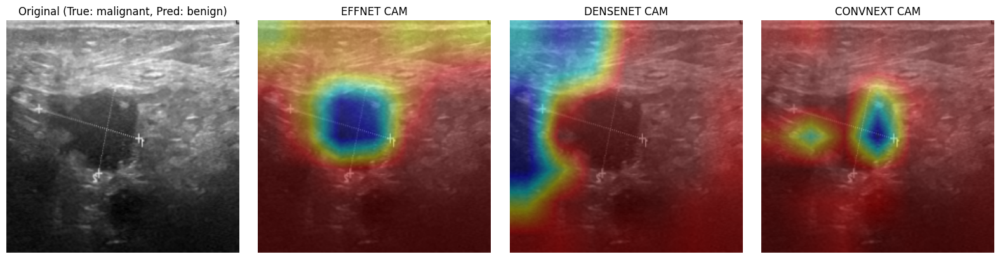


[TEST Evaluation]
[INFO] HybridBackbone initialized. Embedding dim: 3072

[Test (Linear Probe) Classification Report]
              precision    recall  f1-score   support

      benign       0.89      0.95      0.92        44
   malignant       0.94      0.76      0.84        21
      normal       0.93      1.00      0.96        13

    accuracy                           0.91        78
   macro avg       0.92      0.91      0.91        78
weighted avg       0.91      0.91      0.91        78

Global Accuracy: 0.9103


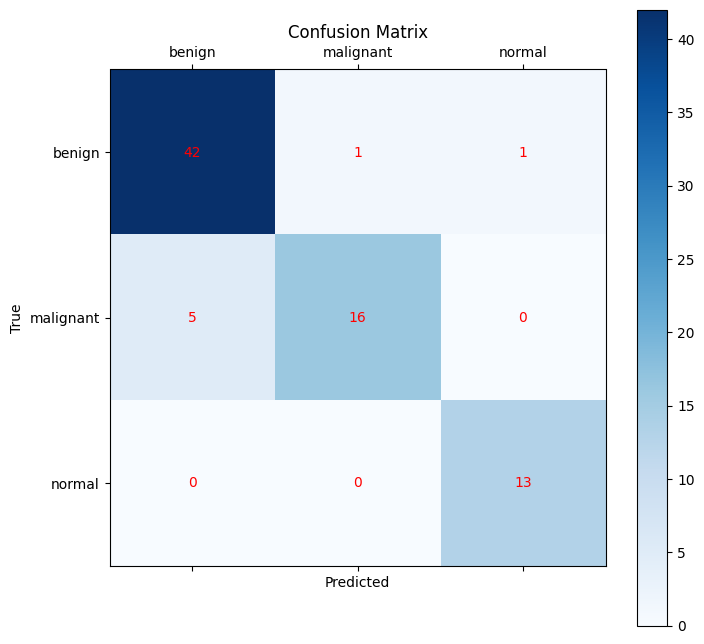

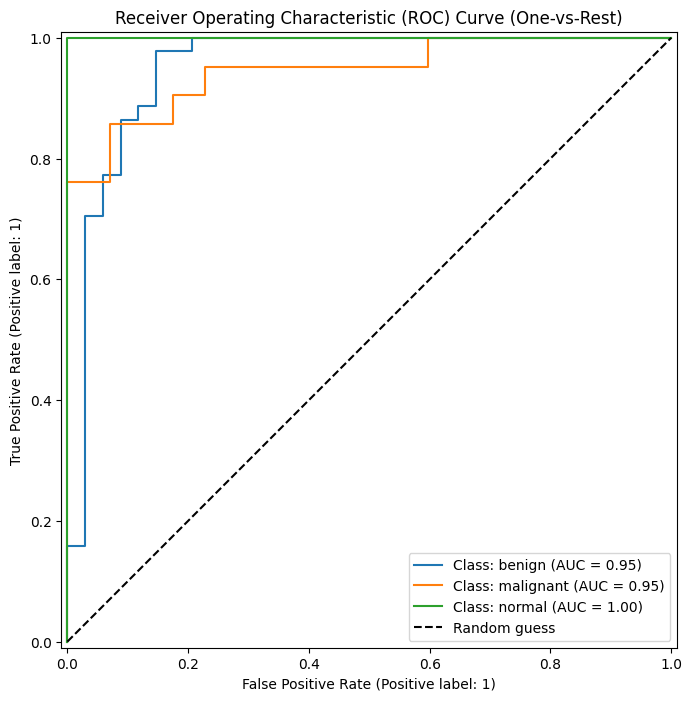

OVR AUC: 0.9656


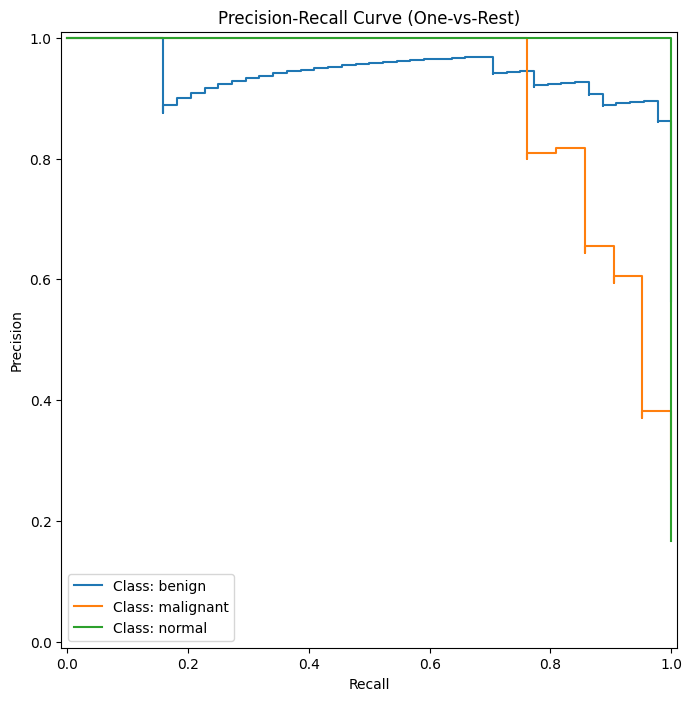


[Test (Linear Probe) Grad-CAM Visualization]


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


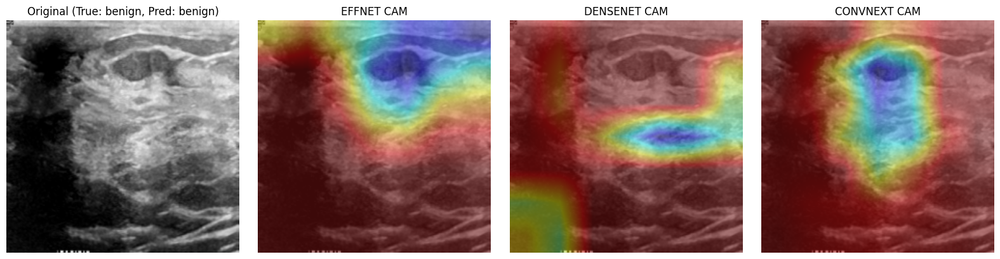

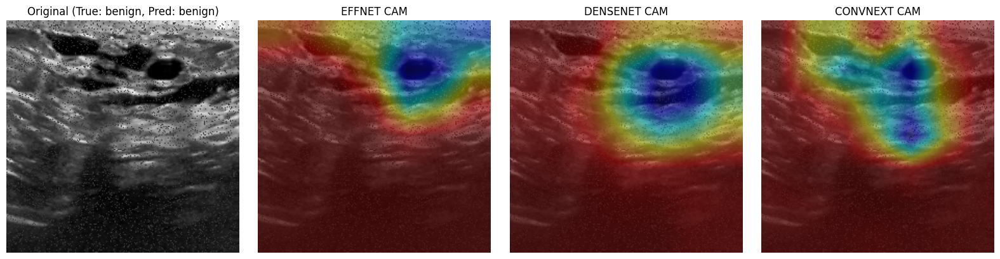

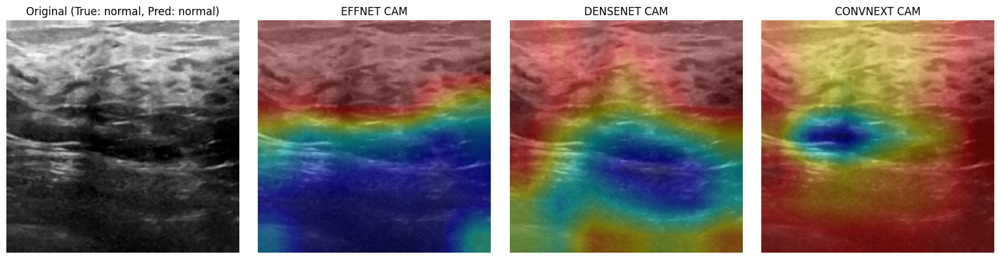

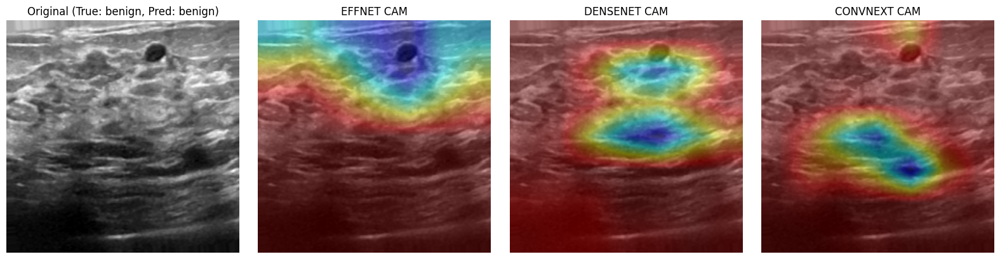

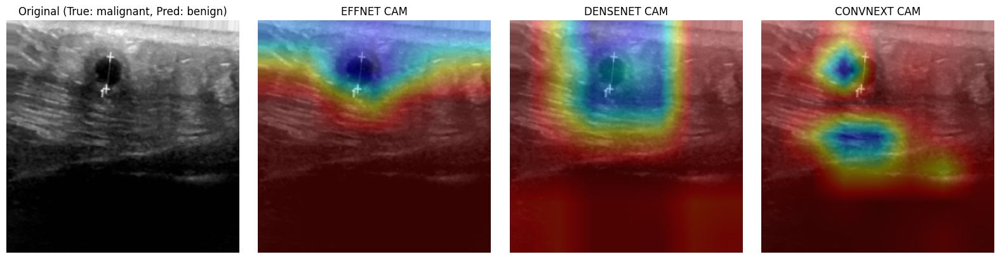


Done.


In [ ]:
# ===========================
# 5. Run the Pipeline
# ===========================
if __name__ == "__main__":
    print("Device:", CFG.DEVICE)

    print("\nDisplaying 5 random pairs of augmented images from the training set:")
    display_ds = USMaskSSL(train_df, ssl=True)
    fig, axes = plt.subplots(5, 2, figsize=(8, 16))
    for i in range(5):
        v1, v2 = display_ds[random.randint(0, len(display_ds) - 1)]
        axes[i, 0].imshow(v1[0].numpy(), cmap='gray')
        axes[i, 0].set_title(f"View 1 - Sample {i+1}")
        axes[i, 0].axis('off')
        axes[i, 1].imshow(v2[0].numpy(), cmap='gray')
        axes[i, 1].set_title(f"View 2 - Sample {i+1}")
        axes[i, 1].axis('off')
    plt.tight_layout()
    plt.show()

    print("\nStarting SSL Pretraining with Hybrid Model...")
    ssl_pretrain(train_df)

    print("\nStarting Linear Probe with Hybrid Model...")
    lp_path = train_supervised(train_df, val_df)
    evaluate(lp_path, val_df, stage_name="Validation (Linear Probe)")

    lp_path = os.path.join(CFG.OUT_DIR, CFG.LP_CKPT)
    if os.path.exists(lp_path):
        print(f"\nLoading and evaluating Linear Probe model from: {lp_path}")
        evaluate(lp_path, val_df, stage_name="Validation (Linear Probe)")

        if test_df is not None and len(test_df) > 0:
            print("\n[TEST Evaluation]")
            evaluate(lp_path, test_df, stage_name="Test (Linear Probe)")
    else:
        print(f"[INFO] Linear Probe model not found at {lp_path}. Please run the training step first.")

    train_df.to_csv(os.path.join(CFG.OUT_DIR, "train_split.csv"), index=False)
    val_df.to_csv(os.path.join(CFG.OUT_DIR, "val_split.csv"), index=False)
    if test_df is not None:
        test_df.to_csv(os.path.join(CFG.OUT_DIR, "test_split.csv"), index=False)
    print("\nDone.")